# 08 · 점에서 로봇팔로 — 관절 공간, 순기구학, 충돌 구

> 로봇팔은 관절 각도를 정하면 손끝 위치가 정해진다. MPPI는 관절 각가속도를 샘플링하고, 손끝 위치와 충돌 구로 비용을 매기면 그대로 로봇팔에 쓸 수 있다.

**지금 위치**

01 상태·입력·모델 → 02 비용 → 03 최적화 → 04 MPC → 05~07 MPPI → **08 로봇팔** → 09 cuRobo Franka → 10~13 프로젝트

**이 노트를 끝내면**
1. 관절 공간과 작업 공간을 구분하고, 2관절 팔의 순기구학(FK)을 직접 유도해 코드로 쓸 수 있다.
2. 로봇팔 모양을 충돌 구로 근사하는 이유와, activation distance η 비용식의 세 구간을 설명할 수 있다.
3. 05~07의 MPPI로 2관절 팔이 장애물을 피해 손끝을 목표로 옮기게 할 수 있다.

**필요한 것:** 01의 rollout, 05의 `mppi_step`, 06의 장애물 비용과 η, 삼각함수(cos, sin) · **예상 시간:** 40분

## 복습 퀴즈 (05~07)

<details><summary>1. MPPI에서 샘플의 가중치는 무엇으로 정해지나? 온도 β를 키우면?</summary>

비용이 낮을수록 가중치가 크다: $\omega_k \propto \exp(-J_k/\beta)$. β를 키우면 가중치가 여러 샘플로 고르게 퍼지고, 줄이면 가장 좋은 몇 개에 몰린다.
</details>

<details><summary>2. 06에서 장애물 비용이 "간격이 η보다 크면 0"인 이유는?</summary>

멀리 있는 장애물은 신경 쓸 필요가 없기 때문이다. 간격이 η 안으로 들어올 때부터 비용이 켜져 미리 밀어낸다.
</details>

<details><summary>3. 07에서 "0 입력 후보"를 일부러 섞는 이유는?</summary>

가속도 0은 지금 속도를 그대로 유지하는 움직임이다. 평균 입력열이 틀렸을 때도 "그냥 이대로 가기"라는 안전한 선택지를 항상 비교하기 위해서다.
</details>

In [1]:
import numpy as np
from common import setup_plot, eta_cost, eta_policy
from course import point_rollout, mppi_step
from arm2d import L1, L2, fk, sphere_centers, sphere_gap, sphere_eta_cost, draw_arm
plt = setup_plot()

## 1. 로봇팔은 점이 아니다

### 문제
지금까지 다룬 카트와 2D 점은 **위치를 직접** 움직였다. x 방향으로 가속하면 x로 움직였다.

로봇팔은 다르다. 우리가 옮기고 싶은 것은 **손끝**인데, 모터는 **관절**에 달려 있다. 관절을 돌리면 손끝이 원을 그리며 움직이고, 두 관절을 함께 돌리면 손끝 움직임은 더 복잡해진다.

### 아이디어
그래서 로봇팔에는 공간이 두 개 있다.

| 공간 | 무엇으로 표현하나 | 2관절 평면 팔 | 누가 쓰나 |
|---|---|---|---|
| **관절 공간**(joint space) | 관절 각도 $q = (q_1, q_2)$ | 각도 2개 [rad] | 모터, 제어 입력 |
| **작업 공간**(task space) | 손끝 위치 $(x, y)$ | 좌표 2개 [m] | 목표, 장애물 |

이 노트에서 쓰는 팔은 바닥에 고정된 **2관절 평면 팔**이다. 첫 링크 길이 $L_1 = 0.5$ m, 둘째 링크 길이 $L_2 = 0.4$ m다.
- $q_1$: 바닥(x축)에서 잰 첫 링크의 각도
- $q_2$: 첫 링크 방향에서 잰 둘째 링크의 각도 (팔꿈치가 얼마나 굽었는지)

## 2. 순기구학 — 관절 각도에서 손끝 위치로

### 문제
관절 각도 $q$를 알면 손끝은 어디에 있을까? 비용(손끝이 목표에서 얼마나 먼가, 팔이 장애물에 닿는가)을 계산하려면 이 답이 꼭 필요하다.

### 아이디어
링크를 하나씩 따라가면 된다. 바닥에서 출발해 첫 링크 방향($q_1$)으로 $L_1$만큼 가면 팔꿈치다. 팔꿈치에서 둘째 링크 방향으로 $L_2$만큼 가면 손끝이다. 둘째 링크의 방향은 바닥 기준으로 $q_1 + q_2$다. 첫 링크가 이미 $q_1$만큼 돌아가 있고, 거기서 $q_2$만큼 더 돌기 때문이다.

### 수식

$$
\text{팔꿈치} = \big(L_1\cos q_1,\ L_1\sin q_1\big),\qquad
\text{손끝} = \text{팔꿈치} + \big(L_2\cos(q_1+q_2),\ L_2\sin(q_1+q_2)\big)
$$

말로 하면, 길이 × (cos, sin)으로 링크 하나씩 이어 붙인다.

관절 각도 → 손끝 위치를 계산하는 이 규칙을 **순기구학**(forward kinematics, FK)이라고 한다. 01의 모델이 "지금 상태 + 입력 → 다음 상태"였다면, FK는 "관절 각도 → 몸 각 부분의 위치"다.

**예측해 보기:** $q = (0, 0)$이면 팔이 x축으로 쭉 펴진다. 손끝은 어디일까? $q = (\pi/2, 0)$이면? $q = (0, \pi/2)$이면?

<details><summary>답</summary>

(0.9, 0), (0, 0.9), (0.5, 0.4). 마지막은 첫 링크가 x축을 따라 0.5 m 간 뒤, 둘째 링크가 위로 0.4 m 꺾인 모양이다.
</details>

아래가 FK를 그대로 옮긴 코드다. `arm2d.py`의 `fk`와 같은 식이다.

q = [0 0] -> 손끝 [0.9 0. ]
q = [1.571 0.   ] -> 손끝 [0.  0.9]
q = [0.    1.571] -> 손끝 [0.5 0.4]


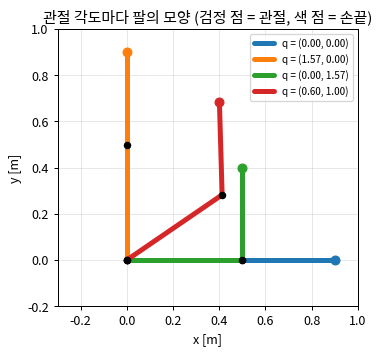

In [2]:
def fk_tip(q):
    # q[..., 2] -> 손끝 위치 [..., 2]
    q1, q2 = q[..., 0], q[..., 1]
    elbow = np.stack([L1 * np.cos(q1), L1 * np.sin(q1)], -1)
    return elbow + np.stack([L2 * np.cos(q1 + q2), L2 * np.sin(q1 + q2)], -1)

for q in [(0, 0), (np.pi / 2, 0), (0, np.pi / 2)]:
    print('q =', np.round(q, 3), '-> 손끝', fk_tip(np.array(q, float)).round(3))

fig, ax = plt.subplots(figsize=(5, 4))
for q, col in [((0, 0), 'tab:blue'), ((np.pi / 2, 0), 'tab:orange'), ((0, np.pi / 2), 'tab:green'), ((0.6, 1.0), 'tab:red')]:
    draw_arm(ax, q, color=col, label=f'q = ({q[0]:.2f}, {q[1]:.2f})')
ax.set_xlim(-0.3, 1.0); ax.set_ylim(-0.2, 1.0); ax.legend(fontsize=8); ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')
ax.set_title('관절 각도마다 팔의 모양 (검정 점 = 관절, 색 점 = 손끝)')
plt.show()

**결과 해석:** 계산 값이 예측과 같다. FK는 cos, sin이 들어간 **비선형** 함수다. 관절 각도를 일정하게 늘려도 손끝은 직선이 아니라 곡선으로 움직인다.

**한 문장으로:** 둘째 링크의 방향이 $q_2$가 아니라 $q_1 + q_2$인 이유를 설명해 보자.

## 3. 반대 방향은 어렵다 — 같은 손끝, 두 자세

### 문제
목표는 작업 공간(손끝 위치)으로 주어진다. 그러면 "손끝을 (0.2, 0.7)에 두려면 관절 각도가 얼마여야 하나?"를 먼저 풀어야 할까?

### 아이디어
이 반대 방향 계산을 **역기구학**(inverse kinematics, IK)이라고 한다. 그런데 답이 하나가 아니다. 2관절 팔만 해도 같은 손끝 위치에 팔꿈치를 위로 굽힌 자세와 아래로 굽힌 자세, 두 가지가 있다. 아래 셀은 코사인 법칙으로 두 답을 구해 그린다. 유도 과정은 중요하지 않으니 결과 그림만 보면 된다.

자세 A q = [0.741 1.266] -> 손끝 [0.2 0.7]
자세 B q = [ 1.844 -1.266] -> 손끝 [0.2 0.7]


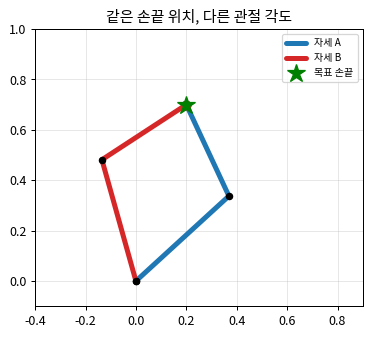

In [3]:
def ik_two_solutions(xy):
    # 2관절 팔 역기구학: 코사인 법칙. 팔꿈치 방향이 다른 두 답을 반환
    x, y = xy
    c2 = (x * x + y * y - L1 ** 2 - L2 ** 2) / (2 * L1 * L2)
    sols = []
    for sign in [+1, -1]:
        q2 = sign * np.arccos(np.clip(c2, -1, 1))
        q1 = np.arctan2(y, x) - np.arctan2(L2 * np.sin(q2), L1 + L2 * np.cos(q2))
        sols.append(np.array([q1, q2]))
    return sols

goal = np.array([0.2, 0.7])
fig, ax = plt.subplots(figsize=(5, 4))
for q, col, name in zip(ik_two_solutions(goal), ['tab:blue', 'tab:red'], ['자세 A', '자세 B']):
    print(name, 'q =', q.round(3), '-> 손끝', fk_tip(q).round(3))
    draw_arm(ax, q, color=col, label=name)
ax.plot(*goal, 'g*', ms=15, label='목표 손끝')
ax.set_xlim(-0.4, 0.9); ax.set_ylim(-0.1, 1.0); ax.legend(fontsize=8); ax.set_title('같은 손끝 위치, 다른 관절 각도')
plt.show()

**결과 해석:** 두 자세 모두 손끝이 정확히 목표에 있다. 관절이 7개인 Franka는 같은 손끝 위치·방향에 자세가 **무수히 많다.** 그래서 IK를 먼저 풀어 관절 목표를 하나 정하는 것은 생각보다 까다롭다.

MPPI는 이 문제를 피해 간다. 관절 공간에서 입력을 샘플링하고, rollout 결과를 FK로 손끝 위치로 바꾼 다음, **손끝이 목표에서 얼마나 먼지를 비용으로** 매기면 된다. 05에서 본 것처럼 MPPI는 비용을 계산만 할 수 있으면 되고, 미분이나 역함수가 필요 없다. 어느 자세로 갈지는 비용이 정한다.

## 4. 입력과 rollout — 관절마다 카트 하나

### 문제
로봇팔의 상태와 입력은 무엇으로 잡아야 할까?

### 아이디어
01의 카트를 떠올리자. 카트는 위치 $p$, 속도 $v$, 입력은 가속도 $u$였다. 관절도 똑같다. 각도 $q_i$, 각속도 $\dot q_i$, 입력은 **각가속도** $\ddot q_i$다. 관절이 2개면 **카트 2개가 나란히 있는 것**과 같다.

| | 1D 카트 (01) | 2D 점 (06) | 2관절 팔 (이 노트) |
|---|---|---|---|
| 상태 | $p, v$ | $(x, y)$, 속도 2개 | $(q_1, q_2)$, 각속도 2개 |
| 입력 | 가속도 1개 | 가속도 2개 | 각가속도 2개 |
| 입력열 모양 | `[K, T]` | `[K, T, 2]` | `[K, T, 2]` |

그래서 06의 `point_rollout`을 **그대로** 쓸 수 있다. 계산은 같고, 숫자의 뜻만 "x, y 위치"에서 "관절 각도 2개"로 바뀐다. 차이는 rollout 뒤에 **FK를 한 번 더** 거쳐야 손끝 위치를 얻는다는 점뿐이다.

```text
각가속도 후보 U[K,T,2] → (rollout) → 관절 각도 Q[K,T+1,2] → (FK) → 손끝 위치 [K,T+1,2] → 비용
```

U (5, 30, 2) → Q (5, 31, 2) → 손끝 (5, 31, 2)


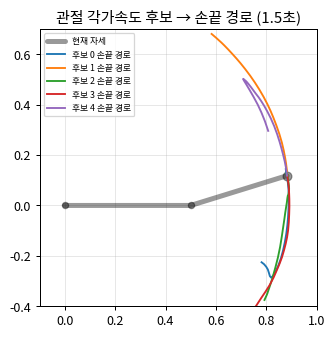

In [4]:
rng = np.random.default_rng(0)
dt, T, K = 0.05, 30, 5
q0, qd0 = np.array([0.0, 0.3]), np.zeros(2)
U = rng.normal(0, 3.0, size=(K, T, 2))                     # 각가속도 후보 [K, T, 2] (rad/s²)
Q, Qd = point_rollout(q0, qd0, U, dt)                      # 관절 각도 [K, T+1, 2]
tips = fk_tip(Q)                                           # 손끝 위치 [K, T+1, 2]
print('U', U.shape, '→ Q', Q.shape, '→ 손끝', tips.shape)

fig, ax = plt.subplots(figsize=(5, 4))
draw_arm(ax, q0, color='k', alpha=0.4, label='현재 자세')
for k in range(K):
    ax.plot(tips[k, :, 0], tips[k, :, 1], '-', lw=1.5, label=f'후보 {k} 손끝 경로')
ax.set_xlim(-0.1, 1.0); ax.set_ylim(-0.4, 0.7); ax.legend(fontsize=7); ax.set_title('관절 각가속도 후보 → 손끝 경로 (1.5초)')
plt.show()

**결과 해석:** 관절 공간에서 뽑은 무작위 입력이 작업 공간에서는 휘어진 손끝 경로가 된다. 손끝은 바닥에서 0.9 m 원 안을 벗어날 수 없다. 팔 길이의 합이 0.9 m이기 때문이다.

## 5. 충돌 검사를 구로 — 왜 공을 붙이나

### 문제
팔이 장애물에 닿는지 판단하려면 **팔 전체**와 장애물 사이 거리가 필요하다. 손끝만 보면 안 된다. 손끝은 멀어도 팔꿈치나 링크 중간이 장애물을 칠 수 있다.

그런데 실제 로봇 링크는 복잡한 곡면(메시)이다. 메시와 장애물 사이 최단 거리를 후보 400개 × 30시점마다 계산하면 너무 느리다.

### 아이디어
링크를 **구 여러 개로 덮는다.** 구는 거리 계산이 아주 쉽다.

$$
\text{간격} = \lVert \text{구 중심} - \text{장애물 중심} \rVert - r_{\text{구}} - r_{\text{장애물}}
$$

말로 하면, 중심 사이 거리에서 두 반지름을 빼면 표면 사이 간격이다. 음수면 겹친 것이다.

이렇게 로봇을 근사한 구들을 **충돌 구**(collision sphere)라고 한다. 계산이 단순해서 GPU에서 수백 개 후보를 한 번에 검사할 수 있다.

구 반지름은 실제 링크보다 조금 더 크게 잡는다. 이 여유분을 **buffer**라고 한다. 구가 링크를 완전히 덮지 못하는 틈, 모델 오차 같은 것에 대비한 안전 여유다. 이 노트의 팔은 링크 두께 반경을 0.04 m로 보고 buffer 0.02 m를 더해 구 반지름 0.06 m를 쓴다.

충돌 구 중심 개수: 8 (링크당 4개)
구별 간격 [m]: [0.579 0.455 0.331 0.208 0.113 0.063 0.057 0.098]
최소 간격 0.057 m (구 #6)


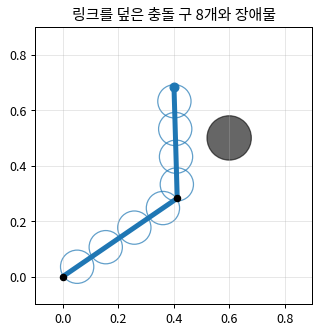

In [5]:
R_LINK, BUFFER = 0.04, 0.02
R = R_LINK + BUFFER          # 충돌 구 반지름 = 링크 반경 + buffer
q_demo = np.array([0.6, 1.0])
centers = sphere_centers(q_demo, n_per_link=4)
print('충돌 구 중심 개수:', len(centers), '(링크당 4개)')

obstacles = [((0.6, 0.5), 0.08)]
gap_all = np.linalg.norm(centers - np.array(obstacles[0][0]), axis=-1) - R - obstacles[0][1]
print('구별 간격 [m]:', gap_all.round(3))
print('최소 간격 %.3f m (구 #%d)' % (gap_all.min(), gap_all.argmin()))

fig, ax = plt.subplots(figsize=(5, 4))
draw_arm(ax, q_demo, spheres=(R, 4))
ax.add_patch(plt.Circle(obstacles[0][0], obstacles[0][1], color='k', alpha=0.6))
ax.set_xlim(-0.1, 0.9); ax.set_ylim(-0.1, 0.9); ax.set_title('링크를 덮은 충돌 구 8개와 장애물')
plt.show()

**결과 해석:** 팔꿈치 너머 둘째 링크의 구 몇 개가 장애물과 가장 가깝다. 손끝 구가 아니라 링크 중간의 구가 가장 가까울 수 있다. 팔 전체를 구로 덮어야 하는 이유다.

**직접 해보기:** `q_demo`를 `[0.3, 1.0]`으로 바꾸면 최소 간격은 어떻게 될까? 그림을 보고 먼저 예상해 보자.

## 6. 충돌 비용 — activation distance η 자세히 보기

### 문제
간격을 계산할 수 있게 됐다. 이 간격을 어떤 비용으로 바꿔야 할까? "겹치면 큰 비용, 아니면 0"으로 하면 두 가지 문제가 있다.
- 장애물 **바로 옆**까지 가도 비용이 0이다. 조금만 흔들려도 부딪힌다.
- 겹치는 후보들끼리 "얼마나 덜 겹쳤나"를 구분하지 못한다.

### 아이디어
06에서 맛본 식을 다시 자세히 보자. 간격이 **η 안으로 들어오기 시작하면** 비용을 켠다. η를 **activation distance**(비용 활성 거리)라고 한다.

$$
C(c) = w\begin{cases}
0 & c \ge \eta \quad\text{(멀다: 비용 없음)}\\[3pt]
\dfrac{(\eta-c)^2}{2\eta} & 0 \le c < \eta \quad\text{(가깝다: 2차로 증가)}\\[8pt]
(\eta - c) - \dfrac{\eta}{2} & c < 0 \quad\text{(겹쳤다: 1차로 증가)}
\end{cases}
$$

여기서 $c$는 구 표면과 장애물 표면 사이 간격, $w$는 이 비용 항의 가중치다.

말로 하면 이렇다.
- η보다 멀면 신경 쓰지 않는다.
- η 안에서는 가까워질수록 비용이 점점 가파르게 커진다. 처음에는 살짝, 붙을수록 세게 민다.
- 겹친 뒤에는 겹친 깊이에 비례해 커진다.

두 식은 $c=0$에서 **값($\eta/2$)과 기울기($-1$)가 모두 이어진다.** 그래서 비용이 갑자기 뛰지 않는다. 겹친 뒤를 2차가 아니라 1차로 둔 이유는, 깊이 겹친 후보의 비용이 폭발적으로 커지지 않게 해서 "덜 겹친 후보"와 "더 겹친 후보"를 구분할 수 있게 하기 위해서다.

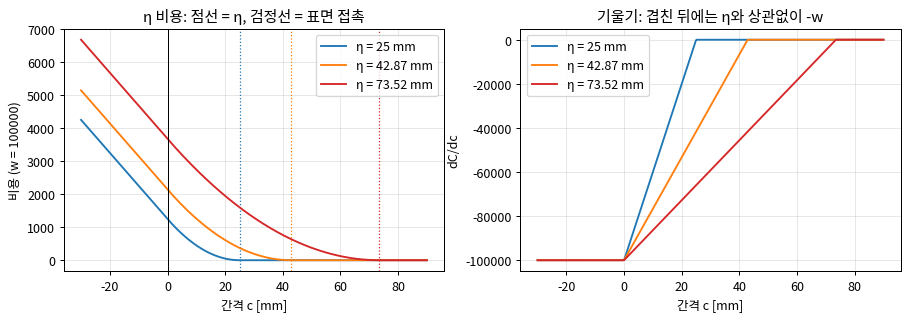

In [6]:
c = np.linspace(-0.03, 0.09, 600)
etas = {'η = 25 mm': 0.025, 'η = 42.87 mm': eta_policy(2.3, 0.5), 'η = 73.52 mm': eta_policy(2.3, 1.0)}
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
for (name, e), col in zip(etas.items(), ['tab:blue', 'tab:orange', 'tab:red']):
    C = eta_cost(c, e, 1e5)
    axs[0].plot(c * 1000, C, color=col, label=name)
    axs[0].axvline(e * 1000, color=col, ls=':', lw=1)
    axs[1].plot(c * 1000, np.gradient(C, c), color=col, label=name)
axs[0].axvline(0, color='k', lw=0.8)
axs[0].set_xlabel('간격 c [mm]'); axs[0].set_ylabel('비용 (w = 100000)'); axs[0].legend(); axs[0].set_title('η 비용: 점선 = η, 검정선 = 표면 접촉')
axs[1].set_xlabel('간격 c [mm]'); axs[1].set_ylabel('dC/dc'); axs[1].legend(); axs[1].set_title('기울기: 겹친 뒤에는 η와 상관없이 -w')
plt.show()

**예측해 보기:** 간격 $c$ = 20 mm에서 η = 25 mm와 η = 73.52 mm 중 어느 쪽 비용이 더 클까? 간격 40 mm에서 η = 25 mm의 비용은?

아래 표는 w = 100000일 때 **구 1개, 1시점**의 비용이다. 25 / 42.87 / 73.52 mm는 이 프로젝트의 LOW / 초기 HIGH / 최종 HIGH 조건에서 쓴 η 값이다(11 노트에서 자세히 다룬다).

In [7]:
gaps_mm = [40, 20, 10, 0, -10]
print('간격 c [mm] | ' + ' | '.join(f'{k:>13s}' for k in etas))
for g in gaps_mm:
    print('%11d | ' % g + ' | '.join('%13.0f' % eta_cost(g / 1000, e, 1e5) for e in etas.values()))

간격 c [mm] |     η = 25 mm |  η = 42.87 mm |  η = 73.52 mm
         40 |             0 |            10 |           764
         20 |            50 |           610 |          1948
         10 |           450 |          1260 |          2744
          0 |          1250 |          2144 |          3676
        -10 |          2250 |          3144 |          4676


**결과 해석:**
- 40 mm에서는 η = 25 mm 비용이 0이다. 아직 비용이 켜지는 거리 밖이다. η = 73.52 mm는 이미 764다.
- 같은 간격이면 η가 클수록 비용이 크다. η를 키우면 **더 멀리서부터, 더 세게** 밀어낸다.
- 겹친 구간(0 → −10 mm)에서는 세 경우 모두 1000씩 늘어난다. 기울기가 $-w$로 같기 때문이다.

이 값은 구 **하나**, 시점 **하나**의 비용이다. 후보 하나의 총비용은 모든 충돌 구 × 모든 시점에서 이 값을 더한 것이다. 구 하나의 비용만 보고 "피할 것이다/부딪힐 것이다"를 단정할 수 없다. 다른 후보들과 총비용을 비교해야 MPPI의 선택이 정해진다.

η는 **비용이 켜지기 시작하는 거리**다. 이만큼의 거리를 지킨다는 보장이 아니다. 목표 비용과의 절충에 따라 η보다 가까이 갈 수도 있다.

**한 문장으로:** 겹친 뒤의 비용을 2차가 아니라 1차로 두는 이유를 설명해 보자.

## 7. 2관절 팔 + MPPI로 장애물 피하기

### 문제
손끝을 (0.88, 0.12)에서 (0.2, 0.7)로 옮기고 싶다. 그 사이에 원형 장애물이 있다. 3절의 두 IK 자세 중 하나를 골라 관절 각도를 직선으로 보간하면 어떻게 될까?

In [8]:
obstacles = [((0.6, 0.5), 0.08)]
ETA = 0.05
for name, qg in zip(['자세 A', '자세 B'], ik_two_solutions(goal)):
    path = np.linspace(q0, qg, 50)              # 관절 각도를 직선으로 보간
    print('%s로 직선 보간: 최소 간격 %.3f m' % (name, sphere_gap(path, obstacles, R).min()))

자세 A로 직선 보간: 최소 간격 -0.133 m
자세 B로 직선 보간: 최소 간격 -0.095 m


두 자세 모두 가는 도중에 장애물과 겹친다(간격이 음수). 목표 자세만 정하고 "그냥 직선으로 가기"로는 안 된다. 움직이는 동안의 충돌까지 비용에 넣고 계획해야 한다.

### 아이디어
05~07에서 만든 MPPI를 그대로 쓴다. 바뀌는 것은 **비용 함수뿐**이다.

$$
J(U) = \sum_t \Big[\,w_{\text{goal}}\,\lVert \text{손끝}_t - \text{목표}\rVert^2 + \underbrace{\sum_{\text{구}} C_\eta(\text{간격})}_{\text{6절의 충돌 비용}} + w_u \lVert u_t \rVert^2\Big] + \text{최종 손끝·속도 항}
$$

손끝 위치는 FK로 계산하고, 충돌 비용은 8개 구와 장애물 사이 간격으로 계산한다. 그다음 04의 MPC처럼 매 스텝 MPPI로 계획하고, 첫 입력만 실행한 뒤 계획을 한 칸 당긴다(warm start).

In [9]:
def arm_cost(U, q, qd):
    # 각가속도 후보 U[K,T,2] -> 총비용 J[K]
    Q, Qd = point_rollout(q, qd, U, dt)
    Qf = Q[:, 1:]                                   # 미래 관절 각도 [K, T, 2]
    d2 = np.sum((fk_tip(Qf) - goal) ** 2, -1)       # 손끝-목표 거리² [K, T]
    c = 10.0 * d2 + sphere_eta_cost(Qf, obstacles, R, ETA, 1000.0) + 1e-3 * np.sum(U ** 2, -1)
    c[:, -1] += 100.0 * d2[:, -1] + 1.0 * np.sum(Qd[:, -1] ** 2, -1)
    return c.sum(-1)

rng = np.random.default_rng(0)
K, T = 400, 30
q, qd = q0.copy(), qd0.copy()
mu, sigma = np.zeros((T, 2)), np.full(2, 3.0)
traj = [q]
for step in range(120):                             # 120 스텝 = 6초
    for _ in range(3):                              # 스텝마다 MPPI 3회 갱신
        mu, sigma, info = mppi_step(mu, sigma, lambda U: arm_cost(U, q, qd), K, 1.0, rng,
                                    u_max=8.0, n_zero=10, n_neg=10, step_size_mean=0.9)
    u = info['best'][0]                             # BEST 후보의 첫 입력만 실행
    q, qd = q + qd * dt + 0.5 * u * dt ** 2, qd + u * dt
    traj.append(q)
    mu = np.concatenate([mu[1:], mu[-1:]])          # warm start: 한 칸 당기기
traj = np.array(traj)

err = np.linalg.norm(fk_tip(traj) - goal, axis=-1)
gap = sphere_gap(traj, obstacles, R)
first = int(np.argmax(err < 0.02))
print('손끝 오차 2 cm 이내 첫 도달: %d 스텝 (%.2f s)' % (first, first * dt))
print('도달 이후 손끝 오차: 평균 %.3f m, 최대 %.3f m' % (err[first:].mean(), err[first:].max()))
print('이동 중 최소 간격 %.3f m (η = %.2f m)' % (gap.min(), ETA))
print('마지막 관절 각도', traj[-1].round(2), '→ 어느 자세?', '자세 A(팔꿈치 q2>0)' if traj[-1, 1] > 0 else '자세 B(q2<0)')

손끝 오차 2 cm 이내 첫 도달: 33 스텝 (1.65 s)
도달 이후 손끝 오차: 평균 0.028 m, 최대 0.056 m
이동 중 최소 간격 0.042 m (η = 0.05 m)
마지막 관절 각도 [0.79 1.15] → 어느 자세? 자세 A(팔꿈치 q2>0)


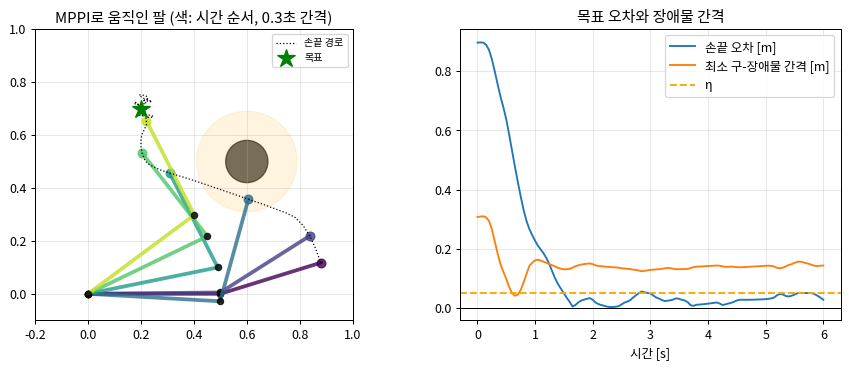

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axs[0]
ax.add_patch(plt.Circle(obstacles[0][0], obstacles[0][1], color='k', alpha=0.6))
ax.add_patch(plt.Circle(obstacles[0][0], obstacles[0][1] + R + ETA, color='orange', alpha=0.12))
for i in range(0, first + 1, 6):
    draw_arm(ax, traj[i], color=plt.cm.viridis(i / max(first, 1)), alpha=0.8, lw=3)
tp = fk_tip(traj)
ax.plot(tp[:, 0], tp[:, 1], 'k:', lw=1, label='손끝 경로')
ax.plot(*goal, 'g*', ms=15, label='목표')
ax.set_xlim(-0.2, 1.0); ax.set_ylim(-0.1, 1.0); ax.legend(fontsize=8)
ax.set_title('MPPI로 움직인 팔 (색: 시간 순서, 0.3초 간격)')
t = np.arange(len(traj)) * dt
axs[1].plot(t, err, label='손끝 오차 [m]')
axs[1].plot(t, gap, label='최소 구-장애물 간격 [m]')
axs[1].axhline(ETA, color='orange', ls='--', label='η')
axs[1].axhline(0, color='k', lw=0.8)
axs[1].set_xlabel('시간 [s]'); axs[1].legend(); axs[1].set_title('목표 오차와 장애물 간격')
plt.show()

**결과 해석:**
- 팔은 장애물을 돌아 손끝을 목표 근처로 옮겼다. 이동 중 최소 간격은 양수다(겹치지 않음). 다만 η보다는 작다. 목표 비용과 충돌 비용이 절충된 결과이고, η가 보장 거리가 아니라는 6절의 설명과 맞다.
- 마지막 자세는 MPPI가 스스로 고른 것이다. 우리는 IK도, 관절 목표도 주지 않았다. 손끝 비용과 충돌 비용만 줬다.
- 도달한 뒤에도 손끝 오차가 몇 cm 안에서 흔들린다(위 출력의 평균·최대). MPPI는 매 스텝 새로 뽑은 무작위 샘플 중 BEST 후보를 고르므로 선택이 조금씩 달라진다. 07의 분산 갱신이나 매끄러운 노이즈 같은 장치를 흔들림을 줄이는 데 쓸 수 있다. 다만 효과는 장면마다 다르다. 이 장면에서 노이즈를 고정된 매끄러운 노이즈로 바꿔 보면 손끝이 목표 2 cm 안에 들어가지 못했다(오차 약 0.14 m). 장치를 더하면 항상 좋아지는 것이 아니라, 장면마다 실제로 돌려서 확인해야 한다.

**직접 해보기:**
1. `ETA`를 0.1로 키워 다시 실행해 보자. 최소 간격과 도달 시간은 어떻게 바뀔까?
2. 장애물을 `((0.45, 0.35), 0.08)`로 옮겨 보자.

<details><summary>관찰 포인트</summary>

η를 키우면 비용이 더 멀리서부터 켜져서, 대체로 장애물에서 더 떨어져 지나간다. 대신 돌아가는 길이 길어져 도달이 늦어질 수 있다. 결과는 seed와 장면에 따라 달라지므로 직접 확인해 보는 것이 중요하다.
</details>

## 핵심 정리

- 로봇팔에는 **관절 공간**(각도, 모터가 쓰는 공간)과 **작업 공간**(손끝 위치, 목표·장애물이 있는 공간)이 있다.
- **순기구학(FK)**은 관절 각도 → 손끝·링크 위치를 계산한다. 링크마다 길이 × (cos, sin)을 이어 붙인다. 반대 방향(IK)은 답이 여러 개라 까다롭다.
- 관절 하나는 카트 하나와 같다. 입력은 각가속도이고, rollout은 01·06과 같다. rollout 뒤에 FK를 거쳐 손끝 비용을 계산한다.
- 팔 모양은 **충돌 구**로 근사한다. 간격 = 중심 거리 − 반지름들로 계산이 쉽고 빠르다. buffer는 반지름에 더한 안전 여유다.
- **η 비용**: 간격이 η보다 멀면 0, η 안에서는 2차, 겹치면 1차로 증가한다. η는 비용이 켜지는 거리이지 보장 거리가 아니다.

## 확인 문제

<details><summary>1. q = (π/2, −π/2)이면 손끝은 어디인가?</summary>

첫 링크가 위로 0.5 m, 둘째 링크 방향은 바닥 기준 π/2 − π/2 = 0이니 오른쪽으로 0.4 m. 손끝 (0.4, 0.5).
</details>

<details><summary>2. 손끝만 장애물에서 멀면 충돌하지 않는다고 할 수 있나?</summary>

아니다. 팔꿈치나 링크 중간이 장애물에 닿을 수 있다. 그래서 링크 전체를 충돌 구로 덮어 검사한다.
</details>

<details><summary>3. 구 반지름에 buffer 20 mm를 더하면, 로그에 기록된 "buffer 포함 간격"과 "buffer 제외 간격"은 얼마나 차이 나나?</summary>

정확히 20 mm. 같은 구, 같은 점이면 반지름만 20 mm 다르기 때문이다. 이 프로젝트 README가 두 값을 따로 표기하는 이유다(12 노트).
</details>

<details><summary>4. 간격이 10 mm일 때 η = 25 mm, w = 100000인 구 1개의 비용을 손으로 계산해 보자.</summary>

(η−c)²/(2η) × w = (0.015)² / 0.05 × 100000 = 0.0045 × 100000 = 450.
</details>

<details><summary>5. MPPI를 로봇팔에 쓸 때 IK가 꼭 필요하지 않은 이유는?</summary>

MPPI는 관절 공간에서 입력을 샘플링하고 비용만 계산하면 된다. 손끝 위치는 FK로 구할 수 있으니, 손끝-목표 거리를 비용에 넣으면 된다. 역함수나 미분이 필요 없다.
</details>

## 실제 프로젝트에서는

| 이 노트 | Franka + cuRobo |
|---|---|
| 2관절, 각가속도 입력 `[K, T, 2]` | 7관절 `[400, 30, 7]` (cuRobo `control_space: 'ACCELERATION'`) |
| `fk_tip` (cos, sin) | cuRobo `CudaRobotModel`이 GPU에서 FK 계산 |
| 링크당 구 4개, 총 8개 | 구 배열 65칸 중 활성 61개 (`content/configs/robot/spheres/franka_mesh.yml`) |
| buffer 0.02 m | `collision_sphere_buffer`: 기본 0.004 m, 이 프로젝트는 0.02 m로 덮어씀 (`hand_experiment.py:90`) |
| η 비용식 | cuRobo 충돌 커널 `sphere_obb_kernel.cu`의 `scale_eta_metric` (같은 세 구간 식) |
| 환경 η 0.05 m, w 1000 | 환경 충돌 η 0.025 m, w 100000 (`particle_mpc.yml`) |

## 다음 노트

[09 · cuRobo로 Franka 계획하기](09_curobo_franka.ipynb): 같은 일을 실제 라이브러리가 7관절 Franka로 어떻게 하는지 cuRobo를 직접 호출해서 확인한다.